# Recorded signals over time

Plots every signal in the ECG, acceleration, and vitals CSV files from session `2026-11-18T21-04-47Z`. Run all cells with a Python kernel that has Matplotlib installed (`python -m pip install matplotlib`). Change `SESSION_NAME` below to plot another session.

The x axis is the board's microsecond timestamp converted to seconds. This recording contains clock jumps, so each increasing-time segment is drawn separately. Without host timestamps, time across a board reset cannot be reconstructed.

In [1]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt

SESSION_NAME = "2026-11-18T21-27-40Z"

# Works when Jupyter starts in the repository root or SerialAnalysis folder.
session_roots = [Path.cwd() / "sessions", Path.cwd() / "SerialAnalysis" / "sessions"]
session_dir = next((root / SESSION_NAME for root in session_roots if (root / SESSION_NAME).is_dir()), None)
if session_dir is None:
    raise FileNotFoundError(f"Session {SESSION_NAME} not found under: {session_roots}")
print(f"Loading {session_dir.resolve()}")

Loading C:\Users\asher\projects\ece198\SerialAnalysis\sessions\2026-11-18T21-27-40Z


In [2]:
def read_signals(path):
    with path.open(newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file, skipinitialspace=True)
        columns = [name.strip() for name in reader.fieldnames or []]
        if not columns or columns[0] != "board_us":
            raise ValueError(f"Expected board_us as the first column in {path}")
        signals = {name: [] for name in columns[1:]}
        times = []
        for row in reader:
            times.append(float(row[reader.fieldnames[0]]) / 1_000_000)
            for name in columns[1:]:
                signals[name].append(float(row[name]))
    return times, signals

recordings = {}
for group in ("ecg", "acceleration", "vitals"):
    path = session_dir / f"{group}.csv"
    recordings[group] = read_signals(path)
    print(f"{path.name}: {len(recordings[group][0]):,} samples")

ecg.csv: 1,912 samples
acceleration.csv: 1,040 samples
vitals.csv: 23 samples


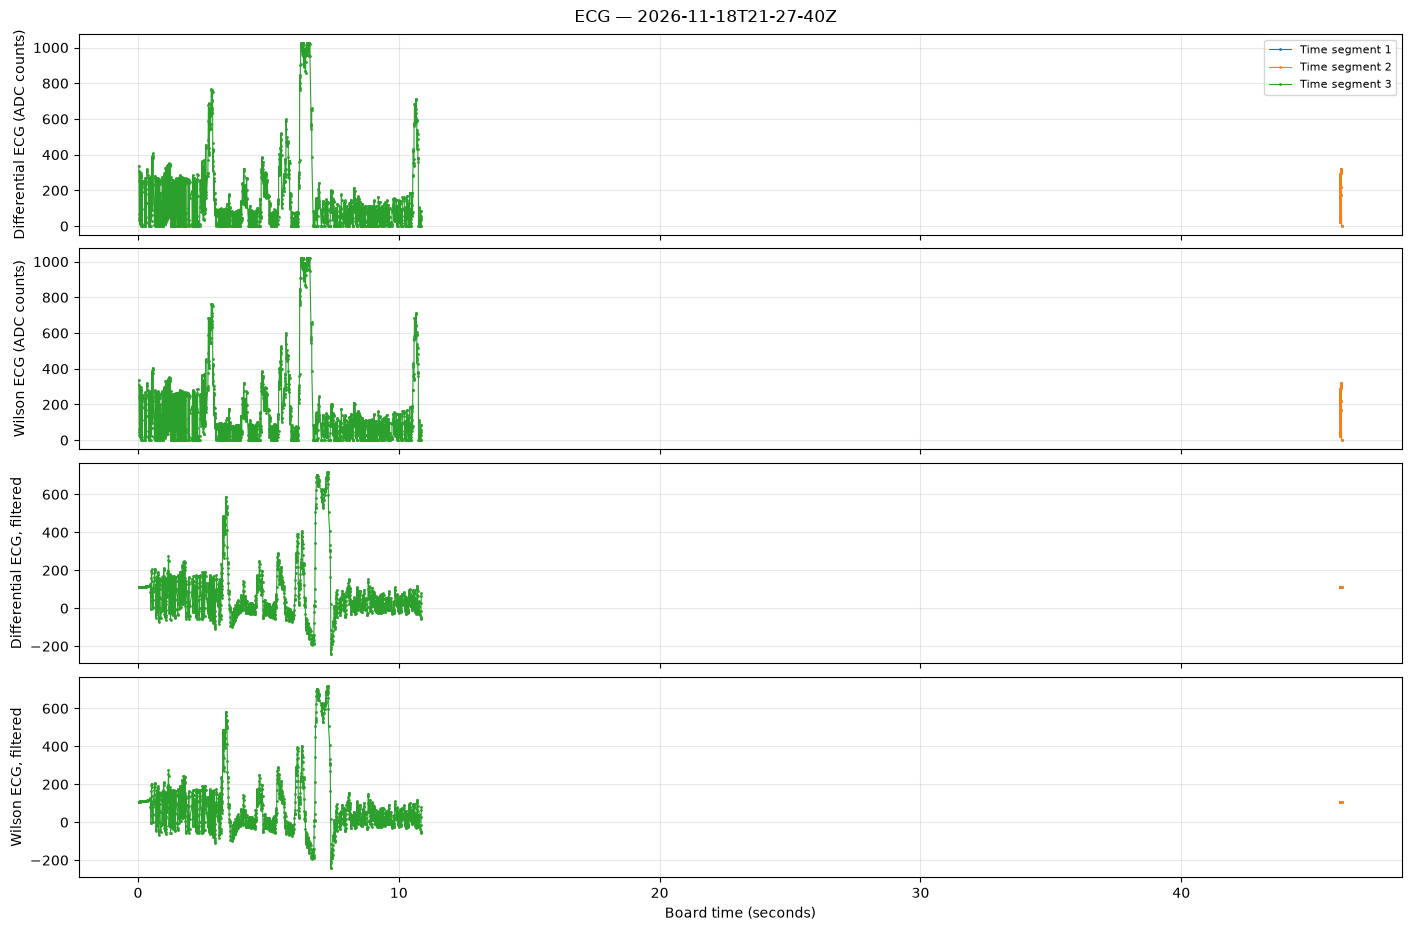

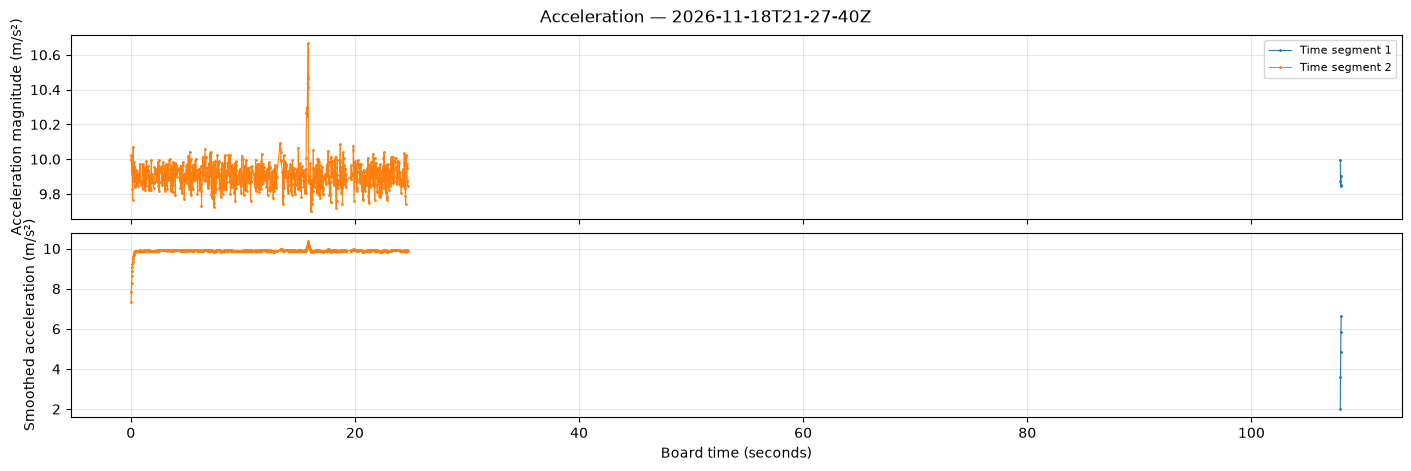

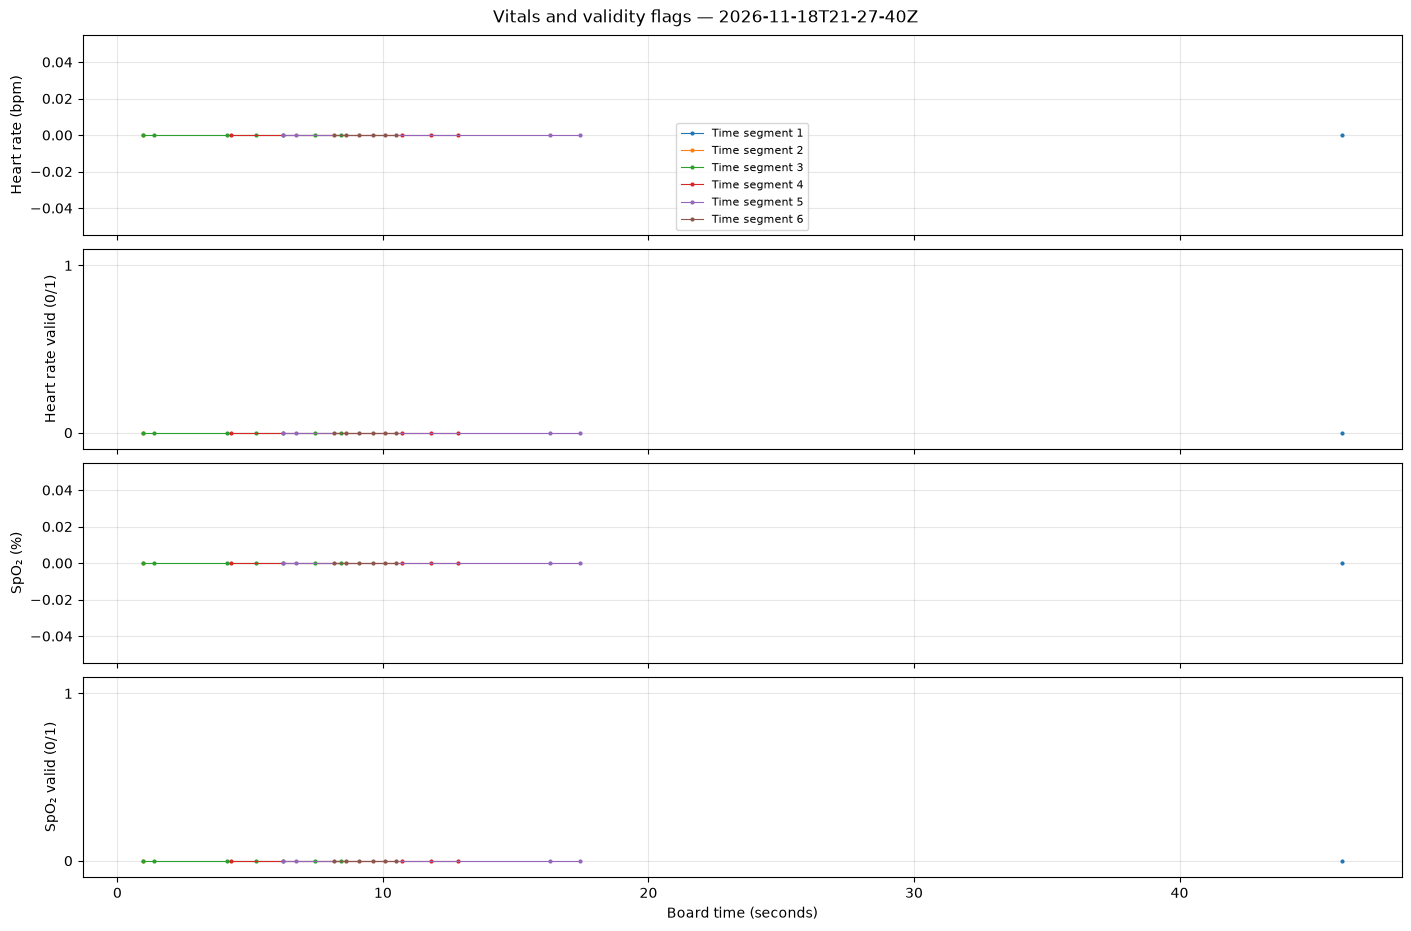

In [3]:
labels = {
    "diff_raw": "Differential ECG (ADC counts)",
    "wilson_raw": "Wilson ECG (ADC counts)",
    "diff_filtered": "Differential ECG, filtered",
    "wilson_filtered": "Wilson ECG, filtered",
    "magnitude_m_s2": "Acceleration magnitude (m/s²)",
    "smoothed_m_s2": "Smoothed acceleration (m/s²)",
    "heart_rate_bpm": "Heart rate (bpm)",
    "heart_rate_valid": "Heart rate valid (0/1)",
    "spo2_percent": "SpO₂ (%)",
    "spo2_valid": "SpO₂ valid (0/1)",
}

def time_segments(times):
    starts = [0] + [i for i in range(1, len(times)) if times[i] < times[i - 1]]
    return [slice(start, end) for start, end in zip(starts, starts[1:] + [len(times)])]

def plot_group(group, title):
    times, signals = recordings[group]
    fig, axes = plt.subplots(len(signals), 1, sharex=True, figsize=(14, 2.3 * len(signals)), layout="constrained")
    if len(signals) == 1:
        axes = [axes]
    segments = time_segments(times)
    for ax, (name, values) in zip(axes, signals.items()):
        for number, segment in enumerate(segments, start=1):
            ax.plot(times[segment], values[segment], linewidth=0.8,
                    marker=".", markersize=2 if len(times) > 1000 else 4,
                    label=f"Time segment {number}")
        ax.set_ylabel(labels.get(name, name))
        ax.grid(alpha=0.3)
        if name.endswith("_valid"):
            ax.set_yticks([0, 1])
            ax.set_ylim(-0.1, 1.1)
    if not times:
        axes[0].text(0.5, 0.5, "No samples in this CSV", transform=axes[0].transAxes, ha="center")
    elif len(segments) > 1:
        axes[0].legend(loc="best", fontsize=8)
    axes[-1].set_xlabel("Board time (seconds)")
    fig.suptitle(f"{title} — {SESSION_NAME}")
    plt.show()

plot_group("ecg", "ECG")
plot_group("acceleration", "Acceleration")
plot_group("vitals", "Vitals and validity flags")